# K Means Clustering

Steps involved in K Means Clustering
1. Initialize K examples of the training data set as Centroids using Kmeans++ or random initialization
2. Loop over the num of iterations to perform the clustering.
   2.a. For each training example compute the euclidian distance from the centroid and assign the cluster
   based on the minimal distance.
   2.b Adjust the centroid of each cluster by taking the average of all the training examples which belonged 
   to that cluster on the basis of the computations performed in step 2.a

In [1]:
#import libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random as rd

In [2]:
# -*- coding: utf-8 -*-
"""
Created on Wed Dec 12 16:35:06 2018

@author: purandur

Modified for this project (the original author credit above is kept). Changes:
  1. k-means++ now measures the distance from each point to its NEAREST chosen centroid
     (before, it added up the distances to all chosen centroids).
  2. The data and centroids are floats (before, integer data made every centroid round down).
  3. An empty cluster is re-seeded with the point that is farthest from its centroid
     (before, an empty cluster produced NaN centroids and RuntimeWarnings).
  4. random_state makes runs repeatable, and n_init restarts keep the best run (lowest WCSS).
  5. The first centroid is picked with an index that always exists (randint includes its upper bound).
  6. Works with any number of features (it was hard-coded to 2), and stops early once nothing changes.
"""
import numpy as np
import random as rd

class Kmeans:
    def __init__(self, X, K, random_state=None, n_init=10):
        self.X = np.asarray(X, dtype=float)
        self.Output = {}
        self.Centroids = np.array([]).reshape(self.X.shape[1], 0)
        self.K = K
        self.m = self.X.shape[0]
        self.n_init = n_init
        self.rng = rd.Random(random_state)

    def kmeanspp(self, X, K):
        i = self.rng.randint(0, X.shape[0] - 1)
        Centroid_temp = np.array([X[i]])
        for k in range(1, K):
            # squared distance from every point to its nearest chosen centroid
            D = np.min(((X[:, None, :] - Centroid_temp[None, :, :]) ** 2).sum(axis=2), axis=1)
            if D.sum() == 0:                         # every point already is a centroid
                i = self.rng.randint(0, X.shape[0] - 1)
            else:
                cumulative_prob = np.cumsum(D / D.sum())
                i = min(int(np.searchsorted(cumulative_prob, self.rng.random())), X.shape[0] - 1)
            Centroid_temp = np.append(Centroid_temp, [X[i]], axis=0)
        return Centroid_temp.T

    def _single_run(self, n_iter):
        Centroids = self.kmeanspp(self.X, self.K)
        labels = None
        for n in range(n_iter):
            # squared Euclidean distance from every point to every centroid
            dist = np.stack([np.sum((self.X - Centroids[:, k]) ** 2, axis=1) for k in range(self.K)], axis=1)
            new_labels = np.argmin(dist, axis=1)
            # give every empty cluster the point that is farthest from its own centroid
            for k in range(self.K):
                if not np.any(new_labels == k):
                    counts = np.bincount(new_labels, minlength=self.K)
                    own_dist = dist[np.arange(self.m), new_labels]
                    own_dist[counts[new_labels] <= 1] = -1   # never take the only member of a cluster
                    new_labels[np.argmax(own_dist)] = k
            if labels is not None and np.array_equal(labels, new_labels):
                break                                        # nothing moved: converged
            labels = new_labels
            for k in range(self.K):                          # adjust the centroids
                Centroids[:, k] = self.X[labels == k].mean(axis=0)
        wcss = sum(np.sum((self.X[labels == k] - Centroids[:, k]) ** 2) for k in range(self.K))
        return Centroids, labels, wcss

    def fit(self, n_iter):
        best = None
        for _ in range(self.n_init):
            run = self._single_run(n_iter)
            if best is None or run[2] < best[2]:
                best = run
        self.Centroids, self.labels_, self.wcss_ = best
        self.Output = {k + 1: self.X[self.labels_ == k] for k in range(self.K)}

    def predict(self):
        return self.Output, self.Centroids.T

    def WCSS(self):
        wcss = 0
        for k in range(self.K):
            wcss += np.sum((self.Output[k + 1] - self.Centroids[:, k]) ** 2)
        return wcss

In [3]:
dataset=pd.read_csv('Mall_Customers.csv')

In [4]:
X = dataset.iloc[:, [3, 4]].values

In [5]:
dataset.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [6]:
m=X.shape[0]
n_iter=100

In [7]:
#from Kmeans import Kmeans
from sklearn.cluster import KMeans

In [8]:
#to find optimum number of clusters use elbow method
WCSS_array=np.array([])
for K in range(1,11):
    kmeans=Kmeans(X,K,random_state=42)
    kmeans.fit(n_iter)
    Output,Centroids=kmeans.predict()
    wcss=0
    for k in range(K):
        wcss+=np.sum((Output[k+1]-Centroids[k,:])**2)
    #WCSS_array=np.append(WCSS_array,kmeans.WCSS())
    WCSS_array=np.append(WCSS_array,wcss)

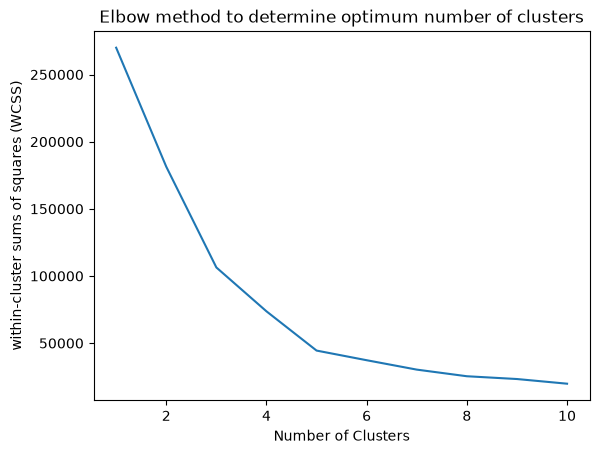

In [9]:
K_array=np.arange(1,11,1)
plt.plot(K_array,WCSS_array)
plt.xlabel('Number of Clusters')
plt.ylabel('within-cluster sums of squares (WCSS)')
plt.title('Elbow method to determine optimum number of clusters')
plt.show()

The idea is that we want a small WCSS, but that the WCSS tends to decrease toward 0 as we increase k (the WCSS is 0 when k is equal to the number of data points in the dataset, because then each data point is its own cluster, and there is no error between it and the center of its cluster). So our goal is to choose a small value of k that still has a low WCSS, and the elbow usually represents where we start to have diminishing returns by increasing k.

In [10]:
#based on these observations we choose 5 as optimum number of clusters
K=5

In [11]:
kmeans=Kmeans(X,K,random_state=42)
kmeans.fit(n_iter)
Output,Centroids=kmeans.predict()

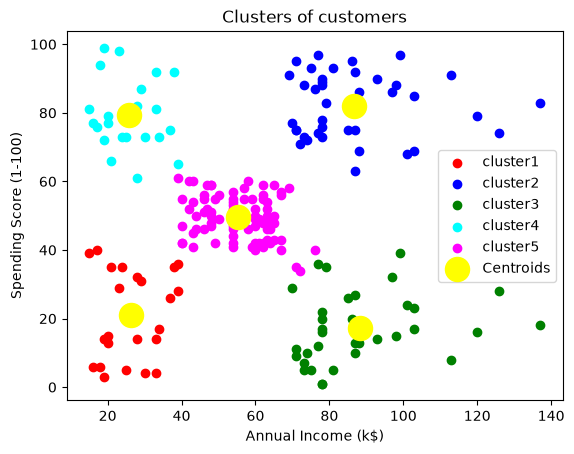

In [12]:
color=['red','blue','green','cyan','magenta']
labels=['cluster1','cluster2','cluster3','cluster4','cluster5']
for k in range(K):
    plt.scatter(Output[k+1][:,0],Output[k+1][:,1],c=color[k],label=labels[k])
plt.scatter(Centroids[:,0],Centroids[:,1],s=300,c='yellow',label='Centroids')
plt.title('Clusters of customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

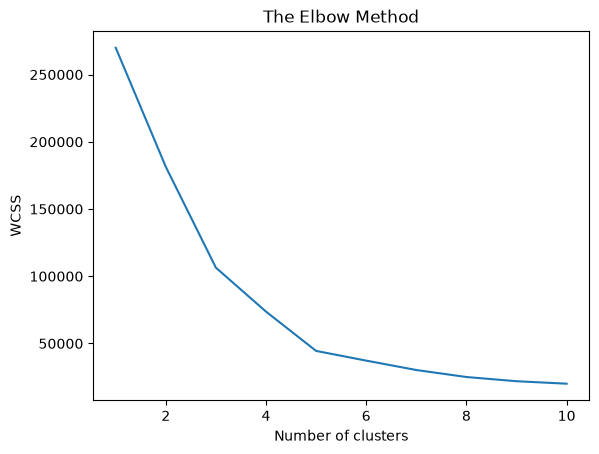

In [13]:
#lets implement the same algorithm using sklearn libraries
# Using the elbow method to find the optimal number of clusters
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', n_init = 10, random_state = 42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [14]:
# Fitting K-Means to the dataset
kmeans = KMeans(n_clusters = 5, init = 'k-means++', n_init = 10, random_state = 42)
y_kmeans = kmeans.fit_predict(X)

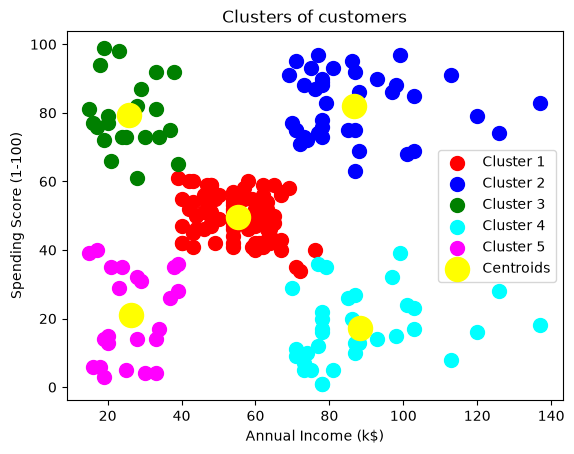

In [15]:
# Visualising the clusters
plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s = 100, c = 'red', label = 'Cluster 1')
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s = 100, c = 'blue', label = 'Cluster 2')
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s = 100, c = 'green', label = 'Cluster 3')
plt.scatter(X[y_kmeans == 3, 0], X[y_kmeans == 3, 1], s = 100, c = 'cyan', label = 'Cluster 4')
plt.scatter(X[y_kmeans == 4, 0], X[y_kmeans == 4, 1], s = 100, c = 'magenta', label = 'Cluster 5')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s = 300, c = 'yellow', label = 'Centroids')
plt.title('Clusters of customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

# Fixing the from-scratch class, and checking it against scikit-learn

The first version of the `Kmeans` class (the author credit in its header is kept) had several problems, which I found by testing it on this data:

1. **Not true k-means++:** the starting centroids were chosen using the sum of the distances to *all* chosen centroids, not the distance to the *nearest* one.
2. **Integer centroids:** the data are integers, so every centroid was rounded down after each update.
3. **Empty clusters** (more common at larger K) gave `NaN` centroids and the `RuntimeWarning` messages the first version showed.
4. **No random seed and a single start:** every run gave a different answer, and an unlucky start gave a poor elbow curve.
5. **A rare crash:** `randint(0, n)` includes `n`, so about 1 run in 200 picked a row that does not exist.

All of these are fixed in the class above, and the notebook has been re-run from the top. Below, the fixed class is compared with scikit-learn's `KMeans`.

## Within-cluster sum of squares (WCSS): from-scratch vs scikit-learn

In [16]:
rows = []
for K in range(1, 11):
    mine = Kmeans(X, K, random_state=42)
    mine.fit(n_iter)
    skl = KMeans(n_clusters=K, init='k-means++', n_init=10, random_state=42).fit(X)
    rows.append({'K': K, 'from scratch': round(mine.WCSS()), 'scikit-learn': round(skl.inertia_)})
wcss_table = pd.DataFrame(rows).set_index('K')
wcss_table['difference'] = wcss_table['from scratch'] - wcss_table['scikit-learn']
wcss_table

,from scratch,scikit-learn,difference
K,,,
1,269981,269981,0
2,181364,181364,0
3,106348,106348,0
4,73680,73680,0
5,44448,44448,0
6,37266,37234,32
7,30273,30241,32
8,25337,25036,301
9,23265,21917,1348


## Are the results stable, and are there empty clusters or NaN values?

In [17]:
results = {}
for K in (5, 8, 10):
    wcss_values, bad_runs = [], 0
    for seed in range(20):
        m = Kmeans(X, K, random_state=seed, n_init=1)          # one start per run: the harshest test
        m.fit(n_iter)
        wcss_values.append(m.WCSS())
        if np.isnan(m.Centroids).any() or min(len(m.Output[k + 1]) for k in range(K)) == 0:
            bad_runs += 1
    results[f'K={K}'] = {'lowest WCSS': round(min(wcss_values)), 'highest WCSS': round(max(wcss_values)),
                         'runs with an empty cluster or NaN (of 20)': bad_runs}
pd.DataFrame(results).T

,lowest WCSS,highest WCSS,runs with an empty cluster or NaN (of 20)
K=5,44448,92312,0
K=8,25036,33268,0
K=10,19656,27458,0


## Do the two methods find the same clusters?

In [18]:
from sklearn.metrics import adjusted_rand_score

mine = Kmeans(X, 5, random_state=42)
mine.fit(n_iter)
skl = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42).fit(X)
print('Adjusted Rand index between the two clusterings (1.0 = identical groups):', round(adjusted_rand_score(mine.labels_, skl.labels_), 3))
print('Cluster sizes, from scratch:', sorted(np.bincount(mine.labels_)))
print('Cluster sizes, scikit-learn:', sorted(np.bincount(skl.labels_)))

Adjusted Rand index between the two clusterings (1.0 = identical groups): 1.0
Cluster sizes, from scratch: [np.int64(22), np.int64(23), np.int64(35), np.int64(39), np.int64(81)]
Cluster sizes, scikit-learn: [np.int64(22), np.int64(23), np.int64(35), np.int64(39), np.int64(81)]


# Choosing K: the silhouette score

The elbow method is a judgement call. The silhouette score measures how well each customer fits its own cluster compared with the nearest other cluster (from -1 to 1, higher is better), so it gives a second opinion.

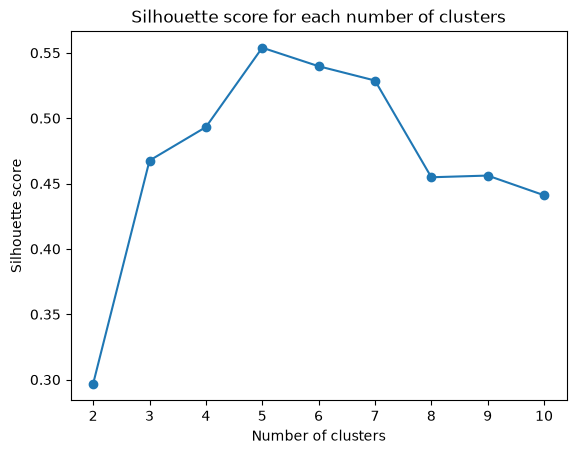

{2: 0.297, 3: 0.468, 4: 0.493, 5: 0.554, 6: 0.54, 7: 0.529, 8: 0.455, 9: 0.456, 10: 0.441}
Best K by silhouette score: 5


In [19]:
from sklearn.metrics import silhouette_score

sil = {K: silhouette_score(X, KMeans(n_clusters=K, init='k-means++', n_init=10, random_state=42).fit_predict(X)) for K in range(2, 11)}
plt.plot(list(sil.keys()), list(sil.values()), marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')
plt.title('Silhouette score for each number of clusters')
plt.show()
print({K: round(v, 3) for K, v in sil.items()})
print('Best K by silhouette score:', max(sil, key=sil.get))

# Who are the five segments?

In [20]:
dataset['Segment'] = skl.labels_
profile = dataset.groupby('Segment').agg(customers=('Segment', 'size'),
                                         avg_income_k=('Annual Income (k$)', 'mean'),
                                         avg_spending_score=('Spending Score (1-100)', 'mean'),
                                         avg_age=('Age', 'mean')).round(1)
profile.sort_values(['avg_income_k', 'avg_spending_score'])

,customers,avg_income_k,avg_spending_score,avg_age
Segment,,,,
2,22,25.7,79.4,25.3
4,23,26.3,20.9,45.2
0,81,55.3,49.5,42.7
1,39,86.5,82.1,32.7
3,35,88.2,17.1,41.1


## Summary

- **The fixed class matches scikit-learn.** For K = 1 to 5 the within-cluster sum of squares is identical (44,448 at K = 5), and at K = 5 the two methods find the same five groups (adjusted Rand index 1.0, same cluster sizes). For K = 6 to 9 the from-scratch result is slightly higher (by 0.1% to 6%), and at K = 10 it is slightly lower. K-means only finds a good local solution, not a guaranteed best one, so small differences like these are normal.
- **No empty clusters or `NaN` centroids** in 60 test runs (20 seeds each at K = 5, 8 and 10, one start per run).
- **A single start can still land in a poor solution.** At K = 5, one-start runs ranged from 44,448 to 92,312. This is normal for K-means, and it is why the class restarts `n_init = 10` times and keeps the best run. With the restarts, the elbow curve is smooth and repeatable.
- **The silhouette score agrees with the elbow:** it peaks at K = 5 (0.554), with K = 6 close behind (0.540).
- **Five segments:** low income and high spending (22 customers), low income and low spending (23), middle income and middle spending (81), high income and high spending (39), and high income and low spending (35). The last group, customers who could spend more but do not, is the one a business would most want to understand.
- **Next steps:** try Age and Genre as extra features (with scaling), compare with other clustering methods such as hierarchical clustering or DBSCAN, and check how stable the segments are on new data.
